## F2 Evaluación

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_F2 = RAIZ / "Formativa2"
CARPETA_DATOS = DIRECTORIO_F2 / "datos"
CARPETA_RESULTADOS = DIRECTORIO_F2 / "resultados"
CARPETA_FIGURAS = DIRECTORIO_F2 / "figuras"

CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

y_test_df = pd.read_csv(
    CARPETA_DATOS / "y_test.csv",
    index_col="EmployeeNumber",
)

probs_df = pd.read_csv(
    CARPETA_RESULTADOS / "probabilidades_prueba.csv",
    index_col="EmployeeNumber",
)

# Comprobar que ambos archivos contienen los mismos empleados.
assert y_test_df.index.is_unique
assert probs_df.index.is_unique
assert set(y_test_df.index) == set(probs_df.index)
assert len(y_test_df) == 441

evaluacion_df = y_test_df.join(
    probs_df,
    how="left",
    validate="one_to_one",
)

assert not evaluacion_df.isna().any().any()
assert set(evaluacion_df["Attrition"].unique()) == {0, 1}
assert evaluacion_df["Probabilidad_salida"].between(0, 1).all()

y_true = evaluacion_df["Attrition"]
y_prob = evaluacion_df["Probabilidad_salida"]

UMBRAL = 0.5
y_pred = (y_prob >= UMBRAL).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

acc = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

print("Matriz: filas = realidad; columnas = predicción")
print("Orden de clases: permanece (0), sale (1)")
print(cm)
print(f"\nAccuracy: {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"AUC: {roc_auc:.4f}")

Matriz: filas = realidad; columnas = predicción
Orden de clases: permanece (0), sale (1)
[[368   2]
 [ 67   4]]

Accuracy: 0.8435
Precision: 0.6667
Recall: 0.0563
F1: 0.1039
AUC: 0.7724


## Matriz de confusión

Se utiliza un umbral de 0,5 y se define la salida como clase positiva
(Attrition = 1). Las filas representan la clase real y las columnas
la predicción.

El modelo detecta 4 de las 71 salidas reales y omite 67. Además, genera
2 falsas alarmas entre los 370 empleados que permanecen.

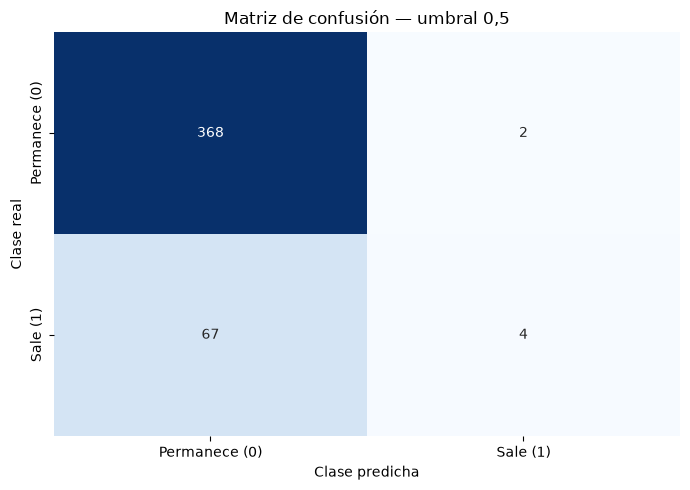

Matriz guardada como figura y tabla.


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Permanece (0)", "Sale (1)"],
    yticklabels=["Permanece (0)", "Sale (1)"],
    ax=ax,
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión — umbral 0,5")

fig.tight_layout()
fig.savefig(
    CARPETA_FIGURAS / "rodrigo_matriz_confusion.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

tabla_confusion = pd.DataFrame(
    cm,
    index=["Real: permanece", "Real: sale"],
    columns=["Predice: permanece", "Predice: sale"],
)

tabla_confusion.to_csv(
    CARPETA_RESULTADOS / "rodrigo_matriz_confusion.csv",
    index_label="Clase real",
)

print("Matriz guardada como figura y tabla.")

## Generación de la Curva ROC y Gráfico de Comparación

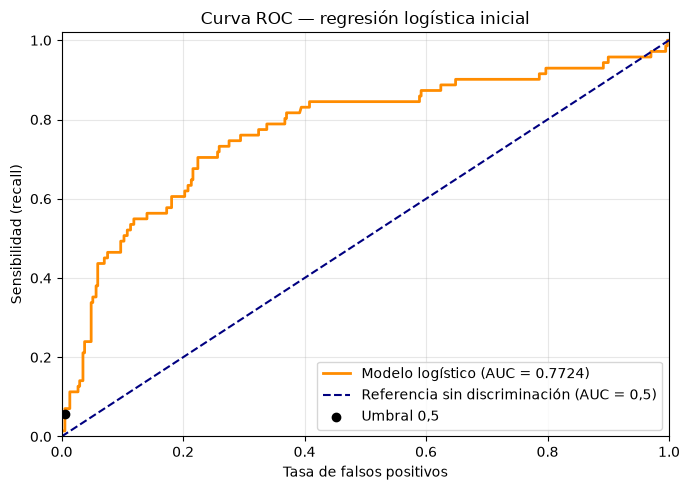

AUC: 0.7724
Curva ROC guardada como figura y tabla.


In [7]:
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"Modelo logístico (AUC = {roc_auc:.4f})",
)

ax.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    label="Referencia sin discriminación (AUC = 0,5)",
)

# Mostrar el desempeño correspondiente al umbral inicial.
tn, fp, fn, tp = cm.ravel()

ax.scatter(
    fp / (fp + tn),
    tp / (tp + fn),
    color="black",
    zorder=3,
    label="Umbral 0,5",
)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1.02),
    xlabel="Tasa de falsos positivos",
    ylabel="Sensibilidad (recall)",
    title="Curva ROC — regresión logística inicial",
)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()

fig.savefig(
    CARPETA_FIGURAS / "rodrigo_curva_roc.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

pd.DataFrame({
    "Tasa falsos positivos": fpr,
    "Sensibilidad": tpr,
    "Umbral": thresholds,
}).to_csv(
    CARPETA_RESULTADOS / "rodrigo_curva_roc.csv",
    index=False,
)

print(f"AUC: {roc_auc:.4f}")
print("Curva ROC guardada como figura y tabla.")

In [8]:
# Referencia: asignar permanencia a todos los empleados.
y_pred_referencia = np.zeros(len(y_true), dtype=int)

tabla_metricas = pd.DataFrame(
    {
        "Accuracy": [
            acc,
            accuracy_score(y_true, y_pred_referencia),
        ],
        "Precision": [
            precision,
            precision_score(
                y_true, y_pred_referencia, zero_division=0
            ),
        ],
        "Recall": [
            recall,
            recall_score(
                y_true, y_pred_referencia, zero_division=0
            ),
        ],
        "F1": [
            f1,
            f1_score(
                y_true, y_pred_referencia, zero_division=0
            ),
        ],
        "AUC": [
            roc_auc,
            roc_auc_score(y_true, np.zeros(len(y_true))),
        ],
    },
    index=["Logística: umbral 0,5", "Referencia: todos permanecen"],
)

tabla_metricas.to_csv(
    CARPETA_RESULTADOS / "rodrigo_metricas_comparacion.csv",
    index_label="Modelo",
)

evaluacion_exportar = evaluacion_df.copy()
evaluacion_exportar["Prediccion_umbral_0_5"] = y_pred

evaluacion_exportar.to_csv(
    CARPETA_RESULTADOS / "rodrigo_predicciones_prueba.csv",
    index_label="EmployeeNumber",
)

display(tabla_metricas.round(4))

mejora_pp = (
    acc - accuracy_score(y_true, y_pred_referencia)
) * 100

print(f"Mejora de accuracy: {mejora_pp:.2f} puntos porcentuales.")
print(
    "La precision de la referencia se registra como 0 por convención "
    "de cálculo: no predice ningún caso positivo."
)

,Accuracy,Precision,Recall,F1,AUC
"Logística: umbral 0,5",0.8435,0.6667,0.0563,0.1039,0.7724
Referencia: todos permanecen,0.8390,0.0000,0.0000,0.0000,0.5000


Mejora de accuracy: 0.45 puntos porcentuales.
La precision de la referencia se registra como 0 por convención de cálculo: no predice ningún caso positivo.


## Interpretación de las métricas y comparación con la referencia

- **Accuracy: 84,35 %.** Se clasifican correctamente 372 de los 441
  empleados. La referencia que predice permanencia para todos alcanza
  83,90 %, por lo que la mejora es de apenas 0,45 puntos porcentuales.
  La exactitud por sí sola resulta insuficiente ante el desbalance.

- **Precision: 66,67 %.** De los seis empleados clasificados como
  salida, cuatro efectivamente salen y dos permanecen. Esta proporción
  se basa en pocas predicciones positivas y debe interpretarse con cautela.

- **Recall: 5,63 %.** Se detectan solo cuatro de las 71 salidas reales.
  Las otras 67 quedan sin identificar. Si el objetivo es detectar
  posibles salidas, esta es la principal limitación del modelo con
  umbral 0,5.

- **F1: 0,1039.** La media armónica entre precision y recall es baja,
  reflejando la escasa detección de la clase positiva.

- **AUC: 0,7724.** Según los rangos orientativos de la plantilla docente,
  la discriminación es aceptable. El valor indica que, al seleccionar
  al azar un empleado que sale y otro que permanece, el modelo asigna
  mayor puntuación al primero aproximadamente el 77,24 % de las veces.
  No significa que clasifique correctamente ese porcentaje de empleados.

El AUC resume la discriminación a través de distintos umbrales; las
métricas anteriores corresponden al umbral fijo de 0,5. Por eso pueden
coexistir un AUC aceptable y un recall bajo.

## Salidas detectadas y omitidas

El conjunto de prueba contiene **71 salidas reales** y **370
permanencias**. Con el umbral de clasificación de 0,5 se obtiene:

| Resultado | Cantidad | Interpretación |
|-----------|---------:|----------------|
| Verdaderos positivos | 4 | Empleados que salen y fueron clasificados como salida. |
| Falsos negativos | 67 | Empleados que salen y fueron clasificados como permanencia. |
| Verdaderos negativos | 368 | Empleados que permanecen y fueron clasificados como permanencia. |
| Falsos positivos | 2 | Empleados que permanecen y fueron clasificados como salida. |

El modelo detecta **4 de las 71 salidas** y omite **67**. Aunque genera
solo dos falsas alarmas, su capacidad de detección con este umbral es
limitada.

## Limitaciones y mejoras para S3

El recall bajo se observa al combinar el umbral 0,5 con las
probabilidades estimadas por este modelo y el desbalance de Attrition.
No puede atribuirse exclusivamente a la ausencia de ponderación de
clases. Con este umbral se obtienen pocas falsas alarmas, pero se omite
la mayoría de las salidas.

Para S3 se compararán modelos y estrategias de imputación, se evaluará
la ponderación de clases y se estudiarán otros umbrales. La selección
del modelo y del umbral se realizará mediante validación dentro del
entrenamiento, reservando prueba para la evaluación final y considerando
el costo relativo de omitir salidas y generar falsas alarmas.

Las asociaciones no demuestran causalidad. Por tratarse de datos
sintéticos, los resultados tienen una finalidad académica y no
justifican directamente políticas de personal.